# Module: Comparison against real observational data

> Do the spectra, colors and luminosities `watercolor` paints land on real survey data? SDSS / DEEP2 colors, WISE colors and GAMA SED stacks, the same comparison set `Mocks_v3_data/reports/patch0` uses for the supermock -- plus the dust calibration that comparison feeds.

## What this compares against

Reduced, bundled copies of the real datasets `Mocks_v3/validation/collect_report_data.py` uses (same cuts), under `watercolor/data/observations/` (~10 MB):

* **SDSS** (`sdss_colors.npz`, 60,000 objects, `0.01<z<0.40`) and **DEEP2** (`DEEP2.npy`) -- four colors, `i` magnitude, their errors, and spec-z. The colors are **`u-g, g-r, r-i, i-z`**: the second column is labelled `g-i` in `Mocks_v3`, which is wrong -- see the check below.
* **AllWISE all-sky locus** (`wise_locus.npz`, 40,000 objects, no redshift) and the **WISExSCOS** photo-z crossmatch (`wise_xscos_photoz.fits`, 4,346 objects) -- `W1-W2, W2-W3, W3-W4, W1`.
* **GAMA median SED stacks** (`gama_sed_stacks.csv`) -- observed-frame `f_nu` [mJy] vs *observed* wavelength (0.75-5 um), median-stacked in `(z, logM*)` bins.

## How a single snapshot is compared to a flux-limited survey

The HACC catalog used here (SciDAC `step_624`) is one **z=0 snapshot**: no redshifts, no selection function. A survey's colors depend strongly on both (`g-r` of the red sequence runs from 0.85 at z=0.05 to 1.85 at z=0.35). So the painted sample is **(z, i)-matched** to the survey: in every narrow redshift bin the whole painted sample is placed at that redshift, and each real galaxy is paired with the painted galaxy nearest to it in apparent `i` magnitude (`SurveyColorEngine`). The painted sample then has the survey's joint redshift-magnitude distribution by construction, and only its *colors* are being tested.

This only makes sense while the z=0 stellar populations are a fair stand-in, i.e. at low redshift: SDSS (`z<0.25` used here), WISE and GAMA. **DEEP2 (z~1) cannot be tested with a z=0 snapshot** -- the mean stellar age of these galaxies (7 Gyr) exceeds the age of the universe at z=1; it needs the matching high-redshift snapshot. Its loader stays here for that.

In [ ]:
#| default_exp obs_comparison

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| export
import os
import numpy as np
from importlib.resources import files as _pkg_files

OBS_DATA_DIR = "data/observations/"

SDSS_COLORS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "sdss_colors.npz"))
DEEP2_COLORS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "DEEP2.npy"))
WISE_LOCUS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "wise_locus.npz"))
WISE_XSCOS_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "wise_xscos_photoz.fits"))
GAMA_SED_FILE = str(_pkg_files("watercolor").joinpath(OBS_DATA_DIR, "gama_sed_stacks.csv"))

## Loading the bundled observational data

Column convention of the SDSS/DEEP2 `colors` arrays: `[u-g, g-r, r-i, i-z, mag_i]` (verified below).

In [ ]:
#| export

# NB the second colour is g-r. Mocks_v3's calibrate_dust.py labels it 'g-i'; the red-sequence ridge
# (0.95 at z=0.1, 1.35 at z=0.2, 1.85 at z=0.35) says otherwise -- see the check below.
SURVEY_COLOR_COLUMNS = ('u-g', 'g-r', 'r-i', 'i-z', 'mag_i')


def _clean_survey_colors(colors:np.ndarray=None, # (N,5) [u-g,g-r,r-i,i-z,mag_i]
                         err_colors:np.ndarray=None, # (N,5) matching errors
                         z:np.ndarray=None, # (N,) spec-z
                         zrange:tuple=(0.0, 10.0), # Redshift selection window
                         mag_range:tuple=(10.0, 28.0), # mag_i selection window
                         color_clip:float=6.0, # |color| < color_clip for the 4 colors
                         )-> tuple: # (colors, err_colors, z), rows passing all cuts
    '''Same cuts Mocks_v3/validation/calibrate_dust.load_survey applies.'''
    colors = np.asarray(colors, dtype=float)
    err_colors = np.asarray(err_colors, dtype=float)
    z = np.asarray(z, dtype=float)
    mag_i = colors[:, 4]
    mask = (np.all(np.isfinite(colors), axis=1) & np.all(np.isfinite(err_colors), axis=1)
            & np.isfinite(z)
            & np.all(err_colors >= 0, axis=1) & np.all(err_colors[:, :4] < 5, axis=1)
            & (z >= zrange[0]) & (z <= zrange[1])
            & (mag_i > mag_range[0]) & (mag_i < mag_range[1])
            & np.all(np.abs(colors[:, :4]) < color_clip, axis=1))
    return colors[mask], err_colors[mask], z[mask]


def load_sdss_colors(path:str=None, # None -> bundled SDSS_COLORS_FILE
                     )-> dict: # colors, err_colors, z, columns -- pre-cut to Mocks_v3's SDSS window (z in [0.01,0.40])
    d = np.load(path or SDSS_COLORS_FILE)
    return dict(colors=d['colors'], err_colors=d['err_colors'], z=d['z'],
               columns=SURVEY_COLOR_COLUMNS)


def load_deep2_colors(path:str=None, # None -> bundled DEEP2_COLORS_FILE
                      )-> dict: # colors, err_colors, z, columns -- cut to Mocks_v3's DEEP2 window (z in [0.05,1.40])
    d = np.load(path or DEEP2_COLORS_FILE, allow_pickle=True)
    colors, err_colors, z = _clean_survey_colors(d['colors'], d['err_colors'], d['zspec'],
                                                 zrange=(0.05, 1.40))
    return dict(colors=colors, err_colors=err_colors, z=z, columns=SURVEY_COLOR_COLUMNS)

In [ ]:
#| export

WISE_VEGA_TO_AB = (2.699, 3.339, 5.174, 6.620)  # W1,W2,W3,W4: AB = Vega + offset
WISE_COLOR_COLUMNS = ('W1-W2', 'W2-W3', 'W3-W4', 'W1')
# The catalogs are in Vega magnitudes and the offsets do NOT cancel in a color:
# (W1-W2)_AB = (W1-W2)_Vega - 0.640, (W2-W3)_AB = Vega - 1.835, (W3-W4)_AB = Vega - 1.446
_WISE_COLOR_VEGA_TO_AB = np.array([WISE_VEGA_TO_AB[0] - WISE_VEGA_TO_AB[1], WISE_VEGA_TO_AB[1] - WISE_VEGA_TO_AB[2],
                                   WISE_VEGA_TO_AB[2] - WISE_VEGA_TO_AB[3], WISE_VEGA_TO_AB[0]])


def load_wise_locus(path:str=None, # None -> bundled WISE_LOCUS_FILE
                    )-> dict: # AB colors/errs from the AllWISE all-sky locus (no redshift)
    '''AllWISE all-sky sample (SNR-cut, W2-W3>1.5 stellar-locus veto -- see
    Mocks_v3/validation/collect_report_data.py; that veto is W2-W3 > 1.5 in
    Vega). Stored in Vega; colors and W1 are converted to AB here.'''
    d = np.load(path or WISE_LOCUS_FILE)
    colors = np.array(d['colors'], dtype=float)
    colors += _WISE_COLOR_VEGA_TO_AB[None, :]
    return dict(colors=colors, err_colors=np.array(d['err_colors'], dtype=float),
               columns=WISE_COLOR_COLUMNS)


def load_wise_xscos(path:str=None, # None -> bundled WISE_XSCOS_FILE
                    )-> dict: # AB colors/errs/z from the WISExSCOS photo-z crossmatch
    from astropy.io import fits
    with fits.open(path or WISE_XSCOS_FILE) as hdul:
        t = hdul[1].data
        mask = np.isfinite(t['z_phot']) & (t['z_phot'] > 0) & (t['z_phot'] < 1)
        for b in (1, 2, 3, 4):
            mask &= np.isfinite(t[f'w{b}mpro']) & np.isfinite(t[f'w{b}sigmpro'])
        w = {b: np.asarray(t[f'w{b}mpro'], dtype=float)[mask] for b in (1, 2, 3, 4)}
        we = {b: np.asarray(t[f'w{b}sigmpro'], dtype=float)[mask] for b in (1, 2, 3, 4)}
        z = np.asarray(t['z_phot'], dtype=float)[mask]
    colors = np.column_stack([w[1] - w[2], w[2] - w[3], w[3] - w[4], w[1]]) + _WISE_COLOR_VEGA_TO_AB[None, :]
    err_colors = np.column_stack([np.hypot(we[1], we[2]), np.hypot(we[2], we[3]),
                                  np.hypot(we[3], we[4]), we[1]])
    return dict(colors=colors, err_colors=err_colors, z=z, columns=WISE_COLOR_COLUMNS)

In [ ]:
#| export

import csv as _csv


def load_gama_sed_stacks(path:str=None, # None -> bundled GAMA_SED_FILE
                         )-> dict: # wave_um, and {(z, logM): f_nu_mJy} for each bin column
    '''GAMA median-stacked observed-frame SEDs in (z, logM*) bins
    (Richard_GAMA_SED_103122_median_stack_z_Mstar_bins.csv) -- already
    reduced observational data, used as-is.'''
    path = path or GAMA_SED_FILE
    with open(path, newline='') as f:
        reader = _csv.reader(f)
        header = next(reader)
        rows = [[float(x) for x in row] for row in reader]
    rows = np.array(rows)
    wave_um = rows[:, 0]
    stacks = {}
    for col_idx, name in enumerate(header[1:], start=1):
        # name like 'f_nu_mJy_z0.1_m10.5' -> ['f','nu','mJy','z0.1','m10.5']
        parts = name.split('_')
        z_val = float(parts[3][1:])
        m_val = float(parts[4][1:])
        stacks[(z_val, m_val)] = rows[:, col_idx]
    return dict(wave_um=wave_um, stacks=stacks)

## Painted colors as a function of the dust model

`observed_ab_mags` is the vectorised photometry used throughout this notebook. `SurveyColorEngine` does the (z, i)-matching described above and makes the dusted colors cheap enough to fit; `calibrate_dust_model` is that fit.

In [ ]:
#| export

from watercolor.cosmic_distance_effects import combine_redshift_and_dimming_effect
from watercolor.dust_model import DustModel, tau_diffuse, tau_birthcloud, dust_emission_template

/home/nramachandra/anaconda3/envs/opencosmo_env/lib/python3.12/site-packages/sedpy/observate.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename, resource_listdir


In [ ]:
#| export

def observed_ab_mags(wave_rest_aa:np.ndarray=None, # Rest-frame wavelength grid (A)
                     spec_rest:np.ndarray=None, # Rest-frame SEDs (Lsun/A), shape (n_gal, n_wave) or (n_wave,)
                     redshift:float=0.1, # Redshift all the SEDs are placed at
                     filters:tuple=None, # (central_wavelengths, bandpass_wavs [um], bandpass_vals, names) from `load_survey_pickle`
                     )-> np.ndarray: # AB magnitudes, shape (n_gal, n_band)
    '''
    `combine_redshift_and_dimming_effect` + the same transmission-weighted
    mean of f_nu `photometry_from_spectra` takes, for many SEDs at once.
    '''
    wave_obs, fnu_mjy = combine_redshift_and_dimming_effect(wave_rest_aa, np.atleast_2d(spec_rest), redshift)
    mags = np.empty((fnu_mjy.shape[0], len(filters[1])))
    for b, (band_wave_um, band_vals) in enumerate(zip(filters[1], filters[2])):
        band_wave_aa = np.asarray(band_wave_um)*1e4
        idx = np.clip(np.searchsorted(wave_obs, band_wave_aa), 1, wave_obs.shape[0] - 1)
        frac = (band_wave_aa - wave_obs[idx - 1])/(wave_obs[idx] - wave_obs[idx - 1])
        fnu_band = fnu_mjy[:, idx - 1]*(1 - frac) + fnu_mjy[:, idx]*frac
        mags[:, b] = -2.5*np.log10(1e3*(fnu_band @ np.asarray(band_vals))) + 23.9
    return mags


class SurveyColorEngine:
    '''
    Dusted survey colors of a painted galaxy sample as a cheap function of
    the dust model, (z, i)-matched to a real spectroscopic survey.

    A single-snapshot catalog has no redshifts or selection function. For
    each narrow redshift bin of the survey, the whole painted sample is
    placed at the bin centre and every real galaxy is paired with the
    painted galaxy closest to it in apparent `i` magnitude (within
    `mag_tol`). The painted sample then has the survey's joint (z, i)
    distribution by construction, and its colors can be compared to the real
    ones object for object. The real galaxies' own measurement errors are
    added to the painted colors.

    Band fluxes are precomputed as sums over the filter curve, so changing
    the dust only costs an `exp` at the filter's wavelength points (same
    trick as `Mocks_v3`'s `BandEngine`).
    '''
    def __init__(self,
                 wave_rest_aa:np.ndarray=None, # Rest-frame wavelength grid (A)
                 spec_rest:np.ndarray=None, # Dust-free rest-frame SEDs (Lsun/A), (n_gal, n_wave)
                 spec_young:np.ndarray=None, # Part of `spec_rest` from stars younger than ~10 Myr, (n_gal, n_wave)
                 logmass:np.ndarray=None, # log10(M*/Msun)
                 logz:np.ndarray=None, # log10(Z/Zsun)
                 log_ssfr:np.ndarray=None, # log10(sSFR [1/yr])
                 survey:dict=None, # From `load_sdss_colors` / `load_deep2_colors`
                 filters:tuple=None, # ugriz filter set from `load_survey_pickle`
                 z_edges:np.ndarray=None, # Redshift bin edges
                 n_real_per_bin:int=2500, # Real galaxies used per redshift bin
                 mag_tol:float=0.2, # Maximum |i_painted - i_real| for a match
                 seed:int=5, # Seed for the survey subsampling and the noise / dust-scatter draws
                 ):
        rng = np.random.default_rng(seed)
        self.logmass, self.logz, self.log_ssfr = (np.asarray(x, dtype=float) for x in (logmass, logz, log_ssfr))
        self.survey, self.mag_tol, self.n_gal = survey, mag_tol, spec_rest.shape[0]
        self.tau_scatter = rng.standard_normal(self.n_gal) # fixed draws: the objective is a smooth function of sigma
        spec_old = spec_rest - spec_young
        self.bins = []
        for z_lo, z_hi in zip(z_edges[:-1], z_edges[1:]):
            z_mid = 0.5*(z_lo + z_hi)
            real = np.where((survey['z'] >= z_lo) & (survey['z'] < z_hi))[0]
            if real.shape[0] == 0:
                continue
            real = rng.choice(real, min(real.shape[0], n_real_per_bin), replace=False)
            wave_obs, fnu_old = combine_redshift_and_dimming_effect(wave_rest_aa, spec_old, z_mid)
            _, fnu_young = combine_redshift_and_dimming_effect(wave_rest_aa, spec_young, z_mid)
            q_old, q_young, wave_band_rest = [], [], []
            for band_wave_um, band_vals in zip(filters[1], filters[2]):
                band_wave_aa, band_vals = np.asarray(band_wave_um)*1e4, np.asarray(band_vals)
                idx = np.clip(np.searchsorted(wave_obs, band_wave_aa), 1, wave_obs.shape[0] - 1)
                frac = (band_wave_aa - wave_obs[idx - 1])/(wave_obs[idx] - wave_obs[idx - 1])
                q_old.append((fnu_old[:, idx - 1]*(1 - frac) + fnu_old[:, idx]*frac)*band_vals)
                q_young.append((fnu_young[:, idx - 1]*(1 - frac) + fnu_young[:, idx]*frac)*band_vals)
                wave_band_rest.append(band_wave_aa/(1 + z_mid))
            self.bins.append(dict(z=z_mid, real=real, q_old=q_old, q_young=q_young, wave_band_rest=wave_band_rest,
                                  noise=rng.standard_normal((real.shape[0], 4))))

    def tau_v(self, dust_model:DustModel, # Dust model
              redshift:float=0.0, # Redshift
              )-> np.ndarray: # Diffuse V-band optical depth of every painted galaxy
        mean = dust_model.tau_v_mean(self.logmass, self.logz, redshift, log_ssfr=self.log_ssfr)
        return np.clip(mean*np.exp(dust_model.sigma*self.tau_scatter), dust_model.tau_min, dust_model.tau_max)

    def magnitudes(self, dust_model:DustModel, # Dust model; None -> dust-free
                   k:int=0, # Redshift-bin index
                   )-> np.ndarray: # AB magnitudes (n_gal, n_band) of the whole painted sample at that bin's redshift
        b = self.bins[k]
        mags = []
        for q_old, q_young, wave_rest in zip(b['q_old'], b['q_young'], b['wave_band_rest']):
            if dust_model is None:
                flux = np.sum(q_old + q_young, axis=1)
            else:
                birth_cloud = np.exp(-tau_birthcloud(wave_rest, dust_model.tau_bc))
                diffuse = np.exp(-self.tau_v(dust_model, b['z'])[:, None]
                                 * tau_diffuse(wave_rest, 1.0, n=dust_model.n, apply_bump=dust_model.apply_bump)[None, :])
                flux = np.sum((q_old + q_young*birth_cloud[None, :])*diffuse, axis=1)
            mags.append(-2.5*np.log10(1e3*flux) + 23.9)
        return np.array(mags).T

    def matched_colors(self, dust_model:DustModel, # Dust model; None -> dust-free
                       add_noise:bool=True, # Add the matched real galaxies' measurement errors to the painted colors
                       )-> dict: # painted / real colors [u-g, g-r, r-i, i-z], plus z, mag_i, painted-galaxy index and redshift-bin index of every pair
        out = dict(painted=[], real=[], z=[], mag_i=[], index=[], zbin=[])
        for k, b in enumerate(self.bins):
            mags = self.magnitudes(dust_model, k)
            i_real = self.survey['colors'][b['real'], 4]
            order = np.argsort(mags[:, 3]); i_sorted = mags[order, 3]
            j = np.clip(np.searchsorted(i_sorted, i_real), 1, self.n_gal - 1)
            j = np.where(np.abs(i_sorted[j - 1] - i_real) < np.abs(i_sorted[j] - i_real), j - 1, j)
            good = np.abs(i_sorted[j] - i_real) < self.mag_tol
            pick = order[j[good]]; m = mags[pick]
            colors = np.column_stack([m[:, 0] - m[:, 1], m[:, 1] - m[:, 2], m[:, 2] - m[:, 3], m[:, 3] - m[:, 4]])
            if add_noise:
                colors = colors + self.survey['err_colors'][b['real'][good], :4]*b['noise'][good]
            out['painted'].append(colors); out['real'].append(self.survey['colors'][b['real'][good], :4])
            out['z'].append(np.full(pick.shape[0], b['z'])); out['mag_i'].append(m[:, 3])
            out['index'].append(pick); out['zbin'].append(np.full(pick.shape[0], k))
        return {key: np.concatenate(val) for key, val in out.items()}

    def objective(self, dust_model:DustModel, # Dust model; None -> dust-free
                  color_weights:tuple=(0.5, 1.0, 1.0, 1.0), # Relative weights of u-g, g-r, r-i, i-z (u-g is the noisiest)
                  )-> float: # Pair-weighted mean over redshift bins of the summed 1-D Wasserstein distances
        from scipy.stats import wasserstein_distance
        matched = self.matched_colors(dust_model)
        total, weight = 0.0, 0.0
        for k in np.unique(matched['zbin']):
            s = matched['zbin'] == k
            if s.sum() < 50:
                continue
            total += s.sum()*sum(w*wasserstein_distance(matched['painted'][s, c], matched['real'][s, c])
                                 for c, w in enumerate(color_weights))
            weight += s.sum()
        return total/weight


def calibrate_dust_model(engine:SurveyColorEngine=None, # Painted sample + survey to match
                         starts:list=None, # Starting points, dicts of DustModel parameters; None -> three generic ones
                         fit:tuple=('a', 'b', 'e', 'n', 'sigma', 'tau_bc'), # Parameters to fit
                         fixed:dict=None, # Parameters held fixed; None -> c = d = mu = 0
                         steps:dict=None, # Initial simplex step per parameter
                         maxfev:int=700, # Function evaluations per start
                         verbose:bool=True,
                         )-> tuple: # (best DustModel, list of (objective, DustModel) for every start)
    '''
    Nelder-Mead fit of the population dust model to the survey's color
    distributions, from several starting points (the surface has several
    near-degenerate minima; keep the best).
    '''
    from scipy.optimize import minimize
    bounds = dict(a=(1e-3, 4.0), b=(-1.5, 1.5), c=(-1.5, 1.5), d=(-2.0, 3.0), e=(-2.0, 2.0),
                  sigma=(0.0, 1.5), n=(-1.0, 0.6), mu=(0.0, 3.0), tau_bc=(0.0, 4.0))
    fixed = dict(c=0.0, d=0.0, mu=0.0) if fixed is None else dict(fixed)
    steps = dict(dict(a=0.15, b=0.2, c=0.2, d=0.3, e=0.2, sigma=0.15, n=0.15, mu=0.1, tau_bc=0.5), **(steps or {}))
    if starts is None:
        starts = [dict(a=0.4, b=0.0, e=0.5, n=-0.1, sigma=0.3, tau_bc=1.0),
                  dict(a=0.3, b=0.2, e=0.3, n=-0.3, sigma=0.3, tau_bc=0.3),
                  dict(a=0.6, b=-0.2, e=0.2, n=-0.3, sigma=0.15, tau_bc=2.0)]

    def model_from(x):
        return DustModel(**dict(fixed, **{name: float(val) for name, val in zip(fit, x)}))

    def cost(x):
        if any(not (bounds[name][0] <= val <= bounds[name][1]) for name, val in zip(fit, x)):
            return 1e3
        return engine.objective(model_from(x))

    results = []
    for start in starts:
        x0 = np.array([start.get(name, DustModel.DEFAULTS[name]) for name in fit], dtype=float)
        simplex = np.vstack([x0] + [x0 + steps[name]*np.eye(len(fit))[k] for k, name in enumerate(fit)])
        res = minimize(cost, x0, method='Nelder-Mead',
                       options=dict(xatol=5e-3, fatol=2e-4, maxfev=maxfev, initial_simplex=simplex))
        results.append((float(res.fun), model_from(res.x)))
        if verbose:
            print(f'objective {res.fun:.4f} after {res.nfev} evaluations: {results[-1][1]}')
    best = min(results, key=lambda r: r[0])[1]
    return best, results

In [ ]:
#| export

LSUN_ERG_S = 3.828e33
TEN_PC_CM = 3.0856775814913673e19
C_ANGSTROM_PER_S = 2.99792458e18
M_I_SUN_AB = 4.58  # absolute AB magnitude of the Sun in SDSS i (Willmer 2018)


def rest_frame_absolute_mags(wave_rest_aa:np.ndarray=None, # Rest-frame wavelength grid (A)
                             spec_rest:np.ndarray=None, # Rest-frame SEDs (Lsun/A), (n_gal, n_wave) or (n_wave,)
                             filters:tuple=None, # Filter set from `load_survey_pickle`
                             )-> np.ndarray: # Rest-frame absolute AB magnitudes, (n_gal, n_band)
    '''SED at 10 pc, no redshift: the same transmission-weighted mean of f_nu as `observed_ab_mags`.'''
    spec_rest = np.atleast_2d(spec_rest)
    fnu = spec_rest*(wave_rest_aa**2/C_ANGSTROM_PER_S)*LSUN_ERG_S/(4*np.pi*TEN_PC_CM**2)   # erg/s/cm2/Hz at 10 pc
    mags = np.empty((fnu.shape[0], len(filters[1])))
    for b, (band_wave_um, band_vals) in enumerate(zip(filters[1], filters[2])):
        band_wave_aa = np.asarray(band_wave_um)*1e4
        idx = np.clip(np.searchsorted(wave_rest_aa, band_wave_aa), 1, wave_rest_aa.shape[0] - 1)
        frac = (band_wave_aa - wave_rest_aa[idx - 1])/(wave_rest_aa[idx] - wave_rest_aa[idx - 1])
        fnu_band = fnu[:, idx - 1]*(1 - frac) + fnu[:, idx]*frac
        mags[:, b] = -2.5*np.log10(np.sum(fnu_band*np.asarray(band_vals)[None, :], axis=1)) - 48.6
    return mags


def taylor2011_log_mass(abs_mag_g:np.ndarray=None, # Rest-frame absolute AB magnitude in SDSS g
                        abs_mag_i:np.ndarray=None, # Rest-frame absolute AB magnitude in SDSS i
                        )-> np.ndarray: # log10 M*/Msun the GAMA SED-fitting mass scale would assign (Taylor et al. 2011, eq. 8)
    '''
    GAMA's stellar masses (Taylor+2011, BC03 + Chabrier) are well described by
    log(M*/L_i) = -0.68 + 0.70 (g-i)_rest, L_i in solar units. Applying it to the
    painted rest-frame colors gives the mass GAMA would have measured for each
    simulated galaxy, independent of the simulation's own mass accounting.
    '''
    log_l_i = -0.4*(np.asarray(abs_mag_i) - M_I_SUN_AB)
    return -0.68 + 0.70*(np.asarray(abs_mag_g) - np.asarray(abs_mag_i)) + log_l_i

In [ ]:
#| hide

# Imports used only by this notebook's demo/comparison cells below (not
# part of the exported watercolor.obs_comparison module). Kept in one
# pure-import cell -- see 04c's note on why (nbdev's docs-build pass only
# re-executes #|export cells, show_doc(...) cells, or cells that themselves
# contain an import; mixing an import into a cell that depends on a later-
# skipped plain cell breaks the docs build).
import time
import matplotlib.pyplot as plt
from watercolor.load_sim_stellar_catalog import (load_hacc_galaxy_data_opencosmo, load_opencosmo_collection,
                                                  load_galaxy_properties, catalog_redshift)
from watercolor.calculate_csp import calc_csp_for_galaxies
from watercolor.dust_attenuation import log_total_stellar_mass, log_total_stellar_metal
from watercolor.dust_model import (load_default_dust_model, log_sfr_from_particles, attenuate,
                                   DUST_MODEL_JSON, DUST_MODEL_JSON_MOCKS_V3)
from watercolor.filter_convolution import load_survey_pickle

In [ ]:
sdss = load_sdss_colors()
deep2 = load_deep2_colors()
wise_locus = load_wise_locus()
wise_xscos = load_wise_xscos()
gama = load_gama_sed_stacks()
SDSS_FILT = load_survey_pickle('SDSS')
WISE_FILT = load_survey_pickle('WISE')

print(f"SDSS: {len(sdss['z'])} objects, z in [{sdss['z'].min():.2f}, {sdss['z'].max():.2f}]")
print(f"DEEP2: {len(deep2['z'])} objects, z in [{deep2['z'].min():.2f}, {deep2['z'].max():.2f}]")
print(f"AllWISE locus: {len(wise_locus['colors'])} objects")
print(f"WISExSCOS: {len(wise_xscos['z'])} objects, z in [{wise_xscos['z'].min():.2f}, {wise_xscos['z'].max():.2f}]")
print(f"GAMA stacks: {len(gama['stacks'])} (z, logM*) bins, wave grid {gama['wave_um'].shape}")
print('GAMA bins:', sorted(gama['stacks'].keys()))

SDSS: 60000 objects, z in [0.01, 0.40]
DEEP2: 12891 objects, z in [0.05, 1.00]
AllWISE locus: 40000 objects
WISExSCOS: 4346 objects, z in [0.01, 0.44]
GAMA stacks: 12 (z, logM*) bins, wave grid (1000,)
GAMA bins: [(0.05, 10.0), (0.05, 10.5), (0.05, 11.0), (0.1, 10.0), (0.1, 10.5), (0.1, 11.0), (0.15, 10.0), (0.15, 10.5), (0.15, 11.0), (0.2, 10.0), (0.2, 10.5), (0.2, 11.0)]


### Which color is the second column?

`Mocks_v3`'s `calibrate_dust.py` labels the columns `[u-g, g-i, r-i, i-z]` (it verified columns 3 and 4 only) and compares them against synthetic `g-i`. The red sequence settles it: its ridge line in SDSS runs `g-r = 0.85, 0.95, 1.15, 1.35, 1.7, 1.85` at `z = 0.05, 0.1, 0.15, 0.2, 0.3, 0.35`, while `g-i` would be ~0.4-0.65 mag redder throughout. The second column follows the `g-r` track, and interpreting it as `g-i` would make the red sequence's `g-r = (g-i) - (r-i)` an impossible 0.4-0.5 at z=0.1.

In [ ]:
print(' z-bin      90th percentile of [col1, col2, col3, col4]      col2 - col3')
for z_lo, z_hi in [(0.03, 0.07), (0.08, 0.12), (0.13, 0.17), (0.18, 0.22), (0.28, 0.32), (0.33, 0.38)]:
    s = (sdss['z'] > z_lo) & (sdss['z'] < z_hi)
    ridge = np.percentile(sdss['colors'][s, :4], 90, axis=0)
    print(f'{z_lo:.2f}-{z_hi:.2f}   {ridge.round(2)}     {ridge[1] - ridge[2]:.2f}')

# red-sequence g-r at z~0.1 is 0.95-1.0; g-i would be ~1.4
s = (sdss['z'] > 0.08) & (sdss['z'] < 0.12)
assert 0.9 < np.percentile(sdss['colors'][s, 1], 90) < 1.1

 z-bin      90th percentile of [col1, col2, col3, col4]      col2 - col3
0.03-0.07   [1.9  0.86 0.43 0.33]     0.43
0.08-0.12   [2.02 0.99 0.46 0.37]     0.53
0.13-0.17   [2.15 1.15 0.49 0.38]     0.67
0.18-0.22   [2.49 1.36 0.56 0.39]     0.81
0.28-0.32   [3.88 1.71 0.65 0.44]     1.05
0.33-0.38   [4.34 1.87 0.68 0.46]     1.18


## The simulated galaxy sample

A Frontier-E extraction in the halo-particles + `galaxy_properties` layout (`Data/fromFE/filtered_haloproperties.hdf5`: the same layout new catalogs will come in, see `01_load_sim_stellar_catalog`). `load_hacc_galaxy_data_opencosmo` assigns each halo's star particles to its galaxies, and `load_galaxy_properties` gives the per-galaxy table (`gal_mass_star`, `gal_sfr`, ...). The current file is small -- 10 haloes of ~1e14 Msun at z = 0.1, i.e. 245 cluster members, almost all quenched -- so this run is a functional test of the pipeline on this layout; the statistics (and any recalibration) wait for the larger extraction. Every galaxy with at least `MIN_PARTICLES` star particles is used. Cells from here on need the external catalog and are `#|eval: false`.

In [ ]:
#|eval: false

CATALOG_FILE = '/lcrc/project/cosmo_ai/nramachandra/Projects/Hydro_paint/Data/fromFE/filtered_haloproperties.hdf5'
MIN_PARTICLES = 5
RECALIBRATE = False   # fit the dust model on this sample and overwrite the bundled calibration (needs a large field sample)

(fof_p, sat_p, gal_tag_p, _, metal_p, mass_p, age_p, *_, mass_formed_p) = load_hacc_galaxy_data_opencosmo(CATALOG_FILE, return_initial_mass=True)
collection = load_opencosmo_collection(CATALOG_FILE)
galprops = load_galaxy_properties(collection)
z_catalog = catalog_redshift(collection)

tags_all, n_part_all = np.unique(gal_tag_p, return_counts=True)
sample_tags = tags_all[n_part_all >= MIN_PARTICLES]
row_of = {t: i for i, t in enumerate(galprops['gal_tag'])}
gal_sfr_gas = np.array([galprops['gal_sfr'][row_of[t]] for t in sample_tags])       # gas-based instantaneous SFR [Msun/yr]
gal_mass_star_cat = np.array([galprops['gal_mass_star'][row_of[t]] for t in sample_tags])

print(f'{len(sample_tags)} galaxies (of {len(tags_all)}) with >= {MIN_PARTICLES} particles, {np.isin(gal_tag_p, sample_tags).sum()} star particles, catalog z = {z_catalog:.3f}; '
      f'median particle mass {np.median(mass_p):.2e} Msun (formed: {np.median(mass_formed_p):.2e}), median mass/formed = {np.median(mass_p/mass_formed_p):.2f}')

Loaded 45194 star particles from 245 galaxies in 10 haloes (membership: nearest galaxy centre within gal_radius; z = 0.100)


245 galaxies (of 245) with >= 5 particles, 45194 star particles, catalog z = 0.100; median particle mass 2.27e+08 Msun (formed: 3.29e+08), median mass/formed = 0.69


Rest-frame, dust-free SEDs of the whole sample in one go (`calc_csp_for_galaxies`: mass-*formed* weights, clipped log-log SSP interpolation, smoothed particle SFH), together with the part of each SED that comes from stars younger than 10 Myr. A second set with every particle treated as a delta burst is kept for the diagnostics below.

In [ ]:
#|eval: false

t0 = time.time()
wave_rest, spec_rest, spec_young = calc_csp_for_galaxies(gal_tag_p, metal_p, mass_formed_p, age_p, sample_tags)
_, spec_rest_delta, spec_young_delta = calc_csp_for_galaxies(gal_tag_p, metal_p, mass_formed_p, age_p, sample_tags, smooth_sfh=False)
print(f'2 x {len(sample_tags)} rest-frame SEDs in {time.time() - t0:.0f}s')

order_p = np.argsort(gal_tag_p, kind='stable')
starts_p = np.searchsorted(gal_tag_p[order_p], sample_tags, side='left')
ends_p = np.searchsorted(gal_tag_p[order_p], sample_tags, side='right')
particles_of = lambda g: order_p[starts_p[g]:ends_p[g]]

n_part = ends_p - starts_p
logmass_s = np.array([float(log_total_stellar_mass(mass_p[particles_of(g)])[0]) for g in range(len(sample_tags))])
logz_s = np.array([float(log_total_stellar_metal(metal_p[particles_of(g)], mass_p[particles_of(g)])[0]) for g in range(len(sample_tags))])
log_sfr_1gyr = np.array([log_sfr_from_particles(age_p[particles_of(g)], mass_p[particles_of(g)], window_gyr=1.0) for g in range(len(sample_tags))])
log_sfr_100myr = np.array([log_sfr_from_particles(age_p[particles_of(g)], mass_p[particles_of(g)], window_gyr=0.1) for g in range(len(sample_tags))])
log_ssfr_s = log_sfr_1gyr - logmass_s
mw_age_s = np.array([np.average(age_p[particles_of(g)], weights=mass_p[particles_of(g)]) for g in range(len(sample_tags))])

l_bol = np.trapezoid(spec_rest, wave_rest, axis=1)
print(f'median M*/L_bol = {np.median(10**logmass_s/l_bol):.2f} Msun/Lsun;  assigned M* / catalog gal_mass_star: median {np.median(10**logmass_s/gal_mass_star_cat):.3f}')

2 x 245 rest-frame SEDs in 1s
median M*/L_bol = 1.71 Msun/Lsun;  assigned M* / catalog gal_mass_star: median 1.000


## Are the simulated stellar populations themselves off?

The first version of this comparison came out far too red, and one suspect was that the per-particle populations of this HACC catalog differ systematically in age / metallicity from the tabular-SFH populations the bundled `Mocks_v3` dust model had been calibrated on. The populations, by stellar mass:

In [ ]:
#|eval: false

log_ssfr_gas = np.log10(np.maximum(gal_sfr_gas, 1e-30)) - logmass_s
log_ssfr_100 = log_sfr_100myr - logmass_s
print(' logM*      n  particles | star-forming fraction (sSFR > 1e-11/yr)  | median log sSFR of those  | mass-weighted | median')
print('                          |  100 Myr    1 Gyr    gas (instantaneous) |  100 Myr   1 Gyr    gas     |  age [Gyr]    | Z/Zsun')
for m_lo, m_hi in [(9.0, 9.5), (9.5, 10.0), (10.0, 10.5), (10.5, 11.0), (11.0, 11.5)]:
    s = (logmass_s >= m_lo) & (logmass_s < m_hi)
    frac, med = [], []
    for ssfr in (log_ssfr_100, log_ssfr_s, log_ssfr_gas):
        sf = ssfr[s] > -11
        frac.append(sf.mean()); med.append(np.median(ssfr[s][sf]) if sf.any() else np.nan)
    print(f'{m_lo:4.1f}-{m_hi:4.1f} {s.sum():5d} {int(np.median(n_part[s])):6d}    |  {frac[0]:6.2f}   {frac[1]:6.2f}   {frac[2]:6.2f}              '
          f'| {med[0]:7.2f}  {med[1]:7.2f}  {med[2]:7.2f}   |    {np.median(mw_age_s[s]):5.2f}      |  {10**np.median(logz_s[s]):.2f}')

print(f'\nparticles above the SSP grid maximum of 1.58 Zsun: {(metal_p > 1.58).mean():.0%};  '
      f'galaxies with no particle younger than 100 Myr: {(log_sfr_100myr <= -3.99).mean():.0%}, younger than 1 Gyr: {(log_sfr_1gyr <= -3.99).mean():.0%}')

 logM*      n  particles | star-forming fraction (sSFR > 1e-11/yr)  | median log sSFR of those  | mass-weighted | median
                          |  100 Myr    1 Gyr    gas (instantaneous) |  100 Myr   1 Gyr    gas     |  age [Gyr]    | Z/Zsun
 9.0- 9.5    31     11    |    0.00     0.00     0.00              |     nan      nan      nan   |     7.52      |  0.64
 9.5-10.0    75     23    |    0.03     0.12     0.04              |   -9.32    -9.90    -9.53   |     6.93      |  0.63
10.0-10.5    76     76    |    0.05     0.26     0.08              |   -9.64   -10.21   -10.34   |     6.47      |  0.95
10.5-11.0    38    240    |    0.00     0.13     0.05              |     nan   -10.35   -10.39   |     7.18      |  1.13
11.0-11.5    16    569    |    0.00     0.00     0.06              |     nan      nan   -10.95   |     8.10      |  1.14

particles above the SSP grid maximum of 1.58 Zsun: 26%;  galaxies with no particle younger than 100 Myr: 98%, younger than 1 Gyr: 84%


**The populations are fine; their *sampling* is the problem.** (The table above is for whatever catalog is loaded; for the SciDAC field sample the description below holds, for a cluster extraction nearly everything is quenched.) Averaged over 1 Gyr, or taken from the star-forming gas, the simulation has a sensible star-forming main sequence (sSFR ~ 1e-10/yr, falling with mass), a quenched fraction that rises from ~30% to ~95% across `logM* = 9.5-11.5`, and mass-weighted ages of 5-9 Gyr. Two things do differ from a tabular-SFH population:

* **Shot noise in the young stars.** One star particle is ~3e8 Msun formed at one instant. Over 100 Myr that is a quantum of 3 Msun/yr -- above the entire main sequence below `logM*~10.5` -- so ~80% of galaxies have *no* particle younger than 100 Myr while 50-75% of them are in fact forming stars, and the few that do have one are outshone by it (a 3 Myr SSP is ~1000x brighter per unit mass than a 10 Gyr one). `smooth_particle_sfh` spreads every particle over the age interval it samples.
* **Metallicities run high**: ~30% of particles lie above the top of the Padova grid (1.58 Zsun) and are clipped to it.

Neither is what made the first comparison fail, though. That was a stack of plain bugs:

## What was actually wrong

Each effect, measured on this sample (whole sample placed at z=0.1, no dust):

In [ ]:
#|eval: false

def colors_at(spec, z=0.1):
    m = observed_ab_mags(wave_rest, spec, z, SDSS_FILT)
    return np.column_stack([m[:, 0] - m[:, 1], m[:, 1] - m[:, 2], m[:, 2] - m[:, 3], m[:, 3] - m[:, 4], m[:, 3]])

col_good = colors_at(spec_rest)
col_delta = colors_at(spec_rest_delta)
col_tilt = colors_at(spec_rest*wave_rest**2)     # the library's L_nu read as if it were L_lambda: an extra lambda^2
fmt = lambda x: np.array2string(np.asarray(x), precision=2, floatmode='fixed', suppress_small=True)

print('median [u-g, g-r, r-i, i-z] at z=0.1, dust-free')
print('  library read as Lsun/A (old)  :', fmt(np.median(col_tilt[:, :4], axis=0)))
print('  library converted L_nu->L_lam :', fmt(np.median(col_good[:, :4], axis=0)),
      '   -> the old SEDs were redder by', fmt(np.median(col_tilt[:, :4] - col_good[:, :4], axis=0)))
print(f'\nSSP weights: mass formed instead of current mass -> {2.5*np.log10(np.median(mass_formed_p/mass_p)):.2f} mag brighter')

sf = log_ssfr_s > -11
print('\nstar-forming galaxies, 5 / 50 / 95th percentile of u-g and i-z:')
print('  particles as delta bursts :', fmt(np.percentile(col_delta[sf, 0], [5, 50, 95])), ' ', fmt(np.percentile(col_delta[sf, 3], [5, 50, 95])))
print('  smoothed particle SFH     :', fmt(np.percentile(col_good[sf, 0], [5, 50, 95])), ' ', fmt(np.percentile(col_good[sf, 3], [5, 50, 95])))
print('quenched galaxies (unchanged by the smoothing):', fmt(np.percentile(col_delta[~sf, 0], [5, 50, 95])), 'vs', fmt(np.percentile(col_good[~sf, 0], [5, 50, 95])))

lsst_names = load_survey_pickle('LSST', sort_by_wavelength=False)[3]
print('\nband order stored in LSST.pickle:', [n.split('_')[1] for n in lsst_names], '-> unpacked as u, g, r, i, z, y by 07_paint / index')

median [u-g, g-r, r-i, i-z] at z=0.1, dust-free
  library read as Lsun/A (old)  : [2.31 1.41 0.77 0.68]
  library converted L_nu->L_lam : [1.66 0.88 0.36 0.29]    -> the old SEDs were redder by [0.66 0.53 0.41 0.39]

SSP weights: mass formed instead of current mass -> 0.41 mag brighter

star-forming galaxies, 5 / 50 / 95th percentile of u-g and i-z:
  particles as delta bursts : [0.70 1.52 1.61]   [0.09 0.23 0.27]
  smoothed particle SFH     : [0.48 1.49 1.58]   [-0.07  0.23  0.26]
quenched galaxies (unchanged by the smoothing): [1.56 1.68 1.77] vs [1.56 1.68 1.77]

band order stored in LSST.pickle: ['z', 'g', 'r', 'y', 'u', 'i'] -> unpacked as u, g, r, i, z, y by 07_paint / index


| # | Problem | Effect | Fix |
|---|---|---|---|
| 1 | The bundled SSP library is native FSPS output, **`L_nu` [Lsun/Hz] per Msun formed** (checked against python-fsps: ratio 1.000), but every consumer treated it as Lsun/A. | A `lambda^2` tilt on every SED: +0.65 in `u-g`, +0.54 in `g-r`, +0.4 in `r-i` and `i-z`. It also left the SEDs ~1e10x too faint, which an earlier commit misdiagnosed as a "per 1e10 Msun" normalisation -- `c/lambda^2` is ~1e10-1e11 /A in the optical, so that factor only fixed the amplitude by coincidence. | `load_fsps_spectral_library` converts to `L_lambda` once, at load time; the 1e10 factor is gone. |
| 2 | SSPs were weighted by the particles' *current* mass. | 0.4 mag too faint (stellar mass loss: median mass/formed = 0.68). | `initial_star_mass` is read and used for the SSP weights; current mass still defines `M*`. |
| 3 | `spec_ssp_lookup`: bilinear weights from absolute (not grid-normalised) distances, two node weights swapped, and no clipping. | The 30% of particles above the grid (Z > 1.58 Zsun) were linearly *extrapolated*; 6% of all particles ended up with negative SSP fluxes. | Clipped bilinear interpolation in (log age, log Z). |
| 4 | Every particle a delta burst. | A galaxy with one fresh particle is the brightest object at its mass, so bursts are over-represented in any flux-limited sample: matched to SDSS the 16th percentiles are `u-g = 0.27`, `i-z = -0.09` (single-particle H-alpha in `i`), against 1.19 and 0.20 observed. | `smooth_particle_sfh`. |
| 5 | `LSST.pickle` stores its bands as `z, g, r, y, u, i`; the notebooks unpack them as `u, g, r, i, z, y`. | The "u,g,r,i,z values look off" impression from `index`: the columns were mislabelled. | `load_survey_pickle` returns bands in wavelength order. |
| 6 | The survey's second color is `g-r`, not `g-i` (inherited label). | Painted `g-i` was being compared with real `g-r`: a spurious +0.4-0.6 "too red". | Relabelled; painted `g-r` is compared. |
| 7 | One uniform random redshift per galaxy in `0.02<z<1.3`, then a magnitude window. | Painted and real samples had different redshift and luminosity distributions, which is most of what a color distribution is. | (z, i)-matching. |
| 8 | Attenuation only, no dust emission. | `W2-W3 = -1.2` AB (bare stellar continuum) against +0.75 to +1.8 observed. | Energy-balance DL07 re-emission (`add_dust_emission`). |
| 9 | The WISE catalogs are Vega; the loaders assumed the Vega-AB offsets cancel in colors. | Observed `W2-W3` was 1.84 too red (and `W1-W2` 0.64) relative to the painted AB colors. | Loaders convert the colors to AB. |
| 10 | The GAMA stacks are on an *observed*-wavelength grid. | -- | Painted stacks are compared in the observed frame. |

With 1-7 fixed (smoothing included), the dust-free painted colors of a field sample are close to SDSS but slightly too *blue* -- the opposite of where this started -- and the `Mocks_v3` dust model does not repair that (numbers for the present sample below; the field-sample numbers are in the Results):

In [ ]:
#|eval: false

def summarize(label, matched):
    q = lambda x: np.percentile(x, [16, 50, 84], axis=0)
    print(f'{label}  ({len(matched["z"])} matched pairs)')
    for c, name in enumerate(SURVEY_COLOR_COLUMNS[:4]):
        print(f'    {name}:  painted 16/50/84 = {fmt(q(matched["painted"])[:, c])}    SDSS = {fmt(q(matched["real"])[:, c])}')

Z_EDGES = np.linspace(0.02, 0.26, 13)
t0 = time.time()
engine = SurveyColorEngine(wave_rest, spec_rest, spec_young, logmass_s, logz_s, log_ssfr_s,
                           survey=sdss, filters=SDSS_FILT, z_edges=Z_EDGES)
print(f'engine built in {time.time() - t0:.0f}s')

engine_delta = SurveyColorEngine(wave_rest, spec_rest_delta, spec_young_delta, logmass_s, logz_s, log_ssfr_s,
                                 survey=sdss, filters=SDSS_FILT, z_edges=Z_EDGES)
summarize('no dust, particles as delta bursts', engine_delta.matched_colors(None))
print(f'    objective = {engine_delta.objective(None):.3f}\n')
del engine_delta

mocks_v3_model = DustModel.load(DUST_MODEL_JSON_MOCKS_V3)
summarize('no dust, smoothed particle SFH', engine.matched_colors(None))
print(f'    objective = {engine.objective(None):.3f}\n')
summarize(f'bundled Mocks_v3 calibration {mocks_v3_model}', engine.matched_colors(mocks_v3_model))
print(f'    objective = {engine.objective(mocks_v3_model):.3f}')

engine built in 1s


no dust, particles as delta bursts  (27809 matched pairs)
    u-g:  painted 16/50/84 = [1.52 1.70 1.86]    SDSS = [1.18 1.76 2.09]
    g-r:  painted 16/50/84 = [0.74 0.96 1.27]    SDSS = [0.58 0.92 1.27]
    r-i:  painted 16/50/84 = [0.31 0.38 0.48]    SDSS = [0.34 0.43 0.51]
    i-z:  painted 16/50/84 = [0.24 0.30 0.32]    SDSS = [0.20 0.31 0.36]
    objective = 0.299

no dust, smoothed particle SFH  (27808 matched pairs)
    u-g:  painted 16/50/84 = [1.50 1.69 1.85]    SDSS = [1.18 1.76 2.09]
    g-r:  painted 16/50/84 = [0.72 0.94 1.25]    SDSS = [0.58 0.92 1.27]
    r-i:  painted 16/50/84 = [0.31 0.38 0.47]    SDSS = [0.34 0.43 0.51]
    i-z:  painted 16/50/84 = [0.24 0.30 0.32]    SDSS = [0.20 0.31 0.36]


    objective = 0.324

bundled Mocks_v3 calibration DustModel(a=0.6955, b=0.1866, c=0.3, d=0.3, e=0, sigma=0.1835, n=0.02154, mu=0.003078, tau_bc=0)  (18824 matched pairs)
    u-g:  painted 16/50/84 = [1.85 2.13 2.33]    SDSS = [1.11 1.61 1.96]
    g-r:  painted 16/50/84 = [0.98 1.24 1.49]    SDSS = [0.50 0.81 1.04]
    r-i:  painted 16/50/84 = [0.48 0.60 0.70]    SDSS = [0.31 0.40 0.46]
    i-z:  painted 16/50/84 = [0.39 0.50 0.56]    SDSS = [0.17 0.29 0.35]
    objective = 1.108


So the hunch about the dust model was right, for a more specific reason than different ages or metallicities. A population dust calibration is tied to the dust-free SEDs it was fit on (`Mocks_v3`'s own production fit has since moved from `a=0.70, b=0.19` to a mass-independent `a=0.41`), and the `Mocks_v3` one has two properties that do not suit a per-particle catalog:

* `tau_V` depends on mass (and redshift) only, `e = 0`: quenched and star-forming galaxies of the same mass get the same dust. Here the star-formation state of every galaxy is known, and SDSS wants the dust on the *star-forming* galaxies -- the quenched red sequence is already in the right place without any.
* No birth-cloud term worth the name (`mu = 0.003`, applied to the whole spectrum). Here the light of <10 Myr stars is known separately (`spec_young`), so the extra Charlot & Fall birth-cloud screen can act on exactly that light (`DustModel.tau_bc`). It is what removes the too-blue `u-g` tail of bursty galaxies, and it cuts the objective in half.

## Calibrating the dust model on watercolor's own SEDs

With `RECALIBRATE = True` this fits `a, b, e, n, sigma, tau_bc` (with `c = d = mu = 0`; one snapshot and one low-z survey constrain neither a metallicity nor a redshift term) to the (z, i)-matched SDSS color distributions: pair-weighted sum over redshift bins and colors of 1-D Wasserstein distances, Nelder-Mead from three starting points (~5 min), and saves the result as the bundled default. The bundled calibration was fit this way on 8000 random galaxies of the SciDAC `step_624` field sample (`logM* = 9.1-11.9`, 60% star-forming); the present cluster-member sample cannot constrain it and is only compared against it.

In [ ]:
#|eval: false

if RECALIBRATE:
    t0 = time.time()
    best_model, fits = calibrate_dust_model(engine)
    print(f'{time.time() - t0:.0f}s')

    # the same fit without the birth-cloud term on the young stars, for comparison
    _, fits_no_bc = calibrate_dust_model(engine, fit=('a', 'b', 'e', 'n', 'sigma'), verbose=False,
                                         starts=[dict(a=0.4, b=0.0, e=0.5, n=-0.1, sigma=0.3), dict(a=0.3, b=0.2, e=0.3, n=-0.3, sigma=0.3)])
    print(f'best objective without tau_bc: {min(f[0] for f in fits_no_bc):.3f}   with: {min(f[0] for f in fits):.3f}   no dust: {engine.objective(None):.3f}')

    best_model.meta = dict(calibrated_to=['SDSS'], z_range=[float(Z_EDGES[0]), float(Z_EDGES[-1])],
                           fit_parameters=['a', 'b', 'e', 'n', 'sigma', 'tau_bc'],
                           objective=float(min(f[0] for f in fits)), objective_without_tau_bc=float(min(f[0] for f in fits_no_bc)), objective_no_dust=float(engine.objective(None)),
                           log_ssfr='star particles younger than 1 Gyr (log_sfr_from_particles, window_gyr=1.0)',
                           library='watercolor calc_csp_for_galaxies: smoothed particle SFH, mass-formed weights, FSPS Padova/BaSeL/Kroupa + nebular',
                           sample=f'{os.path.basename(CATALOG_FILE)} (z = {z_catalog:.3f}), {len(sample_tags)} galaxies with >= {MIN_PARTICLES} particles',
                           note='tau_V = a*10^(b(logM-10))*10^(e(log sSFR+10)), lognormal sigma; Noll+09 slope n (bump tied); '
                                'tau_bc = extra Charlot-Fall birth-cloud optical depth on stars younger than 10 Myr. '
                                'Calibrated by nbs/08_observational_comparison.ipynb')
    best_model.save(DUST_MODEL_JSON)
    print('saved', DUST_MODEL_JSON)
else:
    print('RECALIBRATE is False: keeping the bundled calibration (fit on the SciDAC step_624 field sample)')

RECALIBRATE is False: keeping the bundled calibration (fit on the SciDAC step_624 field sample)


## SDSS colors with the calibrated model

calibrated DustModel(a=0.2647, b=0.4106, c=0, d=0, e=0.3453, sigma=0.1193, n=-0.2963, mu=0, tau_bc=0.6736)  (27704 matched pairs)
    u-g:  painted 16/50/84 = [1.61 1.76 1.93]    SDSS = [1.18 1.75 2.09]


    g-r:  painted 16/50/84 = [0.80 1.03 1.31]    SDSS = [0.58 0.91 1.27]
    r-i:  painted 16/50/84 = [0.35 0.41 0.50]    SDSS = [0.34 0.43 0.50]
    i-z:  painted 16/50/84 = [0.28 0.32 0.34]    SDSS = [0.20 0.31 0.36]


    objective = 0.321


    matched sample: median logM* = 11.02, star-forming fraction = 0.11, median tau_V = 0.08 (star-forming: 0.34)


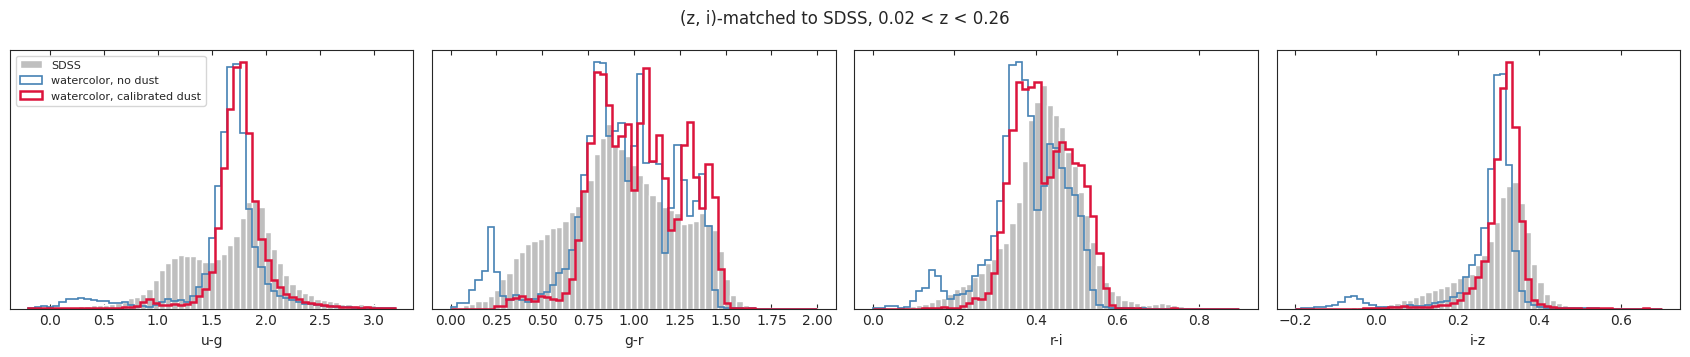

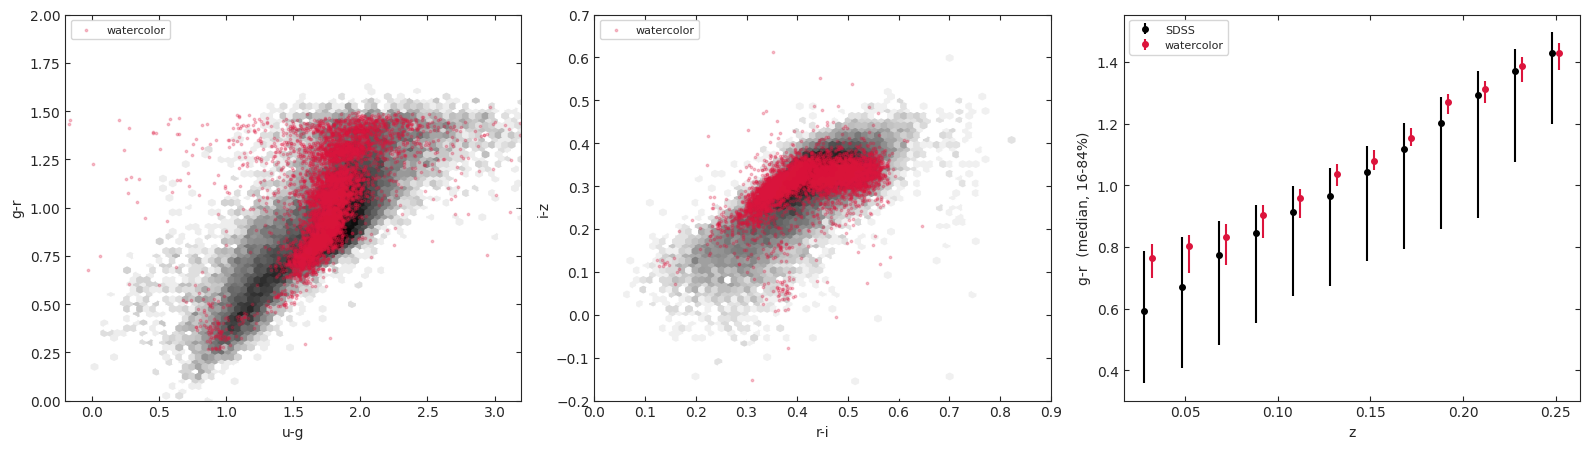

In [ ]:
#|eval: false

dust_model = load_default_dust_model()
matched = engine.matched_colors(dust_model)
matched_nodust = engine.matched_colors(None)
summarize(f'calibrated {dust_model}', matched)
print(f'    objective = {engine.objective(dust_model):.3f}')
tau_matched = np.concatenate([engine.tau_v(dust_model, b['z'])[matched['index'][matched['zbin'] == k]] for k, b in enumerate(engine.bins)])
print(f'    matched sample: median logM* = {np.median(logmass_s[matched["index"]]):.2f}, star-forming fraction = {(log_ssfr_s[matched["index"]] > -11).mean():.2f}, '
      f'median tau_V = {np.median(tau_matched):.2f} (star-forming: {np.median(tau_matched[log_ssfr_s[matched["index"]] > -11]):.2f})')

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
ranges = [(-0.2, 3.2), (0.0, 2.0), (0.0, 0.9), (-0.2, 0.7)]
for c, (ax, name, rg) in enumerate(zip(axes, SURVEY_COLOR_COLUMNS[:4], ranges)):
    bins_c = np.linspace(*rg, 60)
    ax.hist(matched['real'][:, c], bins=bins_c, density=True, color='0.75', label='SDSS')
    ax.hist(matched_nodust['painted'][:, c], bins=bins_c, density=True, histtype='step', color='steelblue', lw=1.2, label='watercolor, no dust')
    ax.hist(matched['painted'][:, c], bins=bins_c, density=True, histtype='step', color='crimson', lw=1.8, label='watercolor, calibrated dust')
    ax.set_xlabel(name); ax.set_yticks([])
axes[0].legend(fontsize=8, loc='upper left'); fig.suptitle('(z, i)-matched to SDSS, 0.02 < z < 0.26'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (cx, cy) in zip(axes[:2], [(0, 1), (2, 3)]):
    ax.hexbin(matched['real'][:, cx], matched['real'][:, cy], gridsize=70, cmap='Greys', bins='log', mincnt=1,
              extent=(*ranges[cx], *ranges[cy]))
    ax.scatter(matched['painted'][::4, cx], matched['painted'][::4, cy], s=3, alpha=0.25, color='crimson', label='watercolor')
    ax.set_xlim(*ranges[cx]); ax.set_ylim(*ranges[cy])
    ax.set_xlabel(SURVEY_COLOR_COLUMNS[cx]); ax.set_ylabel(SURVEY_COLOR_COLUMNS[cy]); ax.legend(fontsize=8, loc='upper left')
ax = axes[2]
for k, b in enumerate(engine.bins):
    s = matched['zbin'] == k
    for key, color in (('real', 'k'), ('painted', 'crimson')):
        lo, med, hi = np.percentile(matched[key][s, 1], [16, 50, 84])
        ax.errorbar(b['z'] + (0.002 if key == 'painted' else -0.002), med, yerr=[[med - lo], [hi - med]], fmt='o', ms=4, color=color,
                    label={'real': 'SDSS', 'painted': 'watercolor'}[key] if k == 0 else None)
ax.set_xlabel('z'); ax.set_ylabel('g-r  (median, 16-84%)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## WISE colors: dust emission

`W1-W2` vs `W2-W3` for the same SDSS-matched painted galaxies, now from the full SED: birth-cloud + diffuse attenuation, then the absorbed luminosity re-emitted with the DL07 template for the galaxy's metallicity and sSFR (`add_dust_emission`). Two real comparison sets: the AllWISE all-sky galaxy locus (no redshifts) and the WISExSCOS photo-z crossmatch, whose W3+W4 detection requirement biases it toward dusty star-forming systems. Both catalogs are in Vega magnitudes; the loaders convert the *colors* to AB (the offsets do not cancel: `W2-W3` shifts by -1.84). Neither shares SDSS's selection -- the locus sample requires W3 and W4 detections and `W2-W3 > 1.5` (Vega), which removes quenched galaxies -- so this is a locus check, not a distribution match.

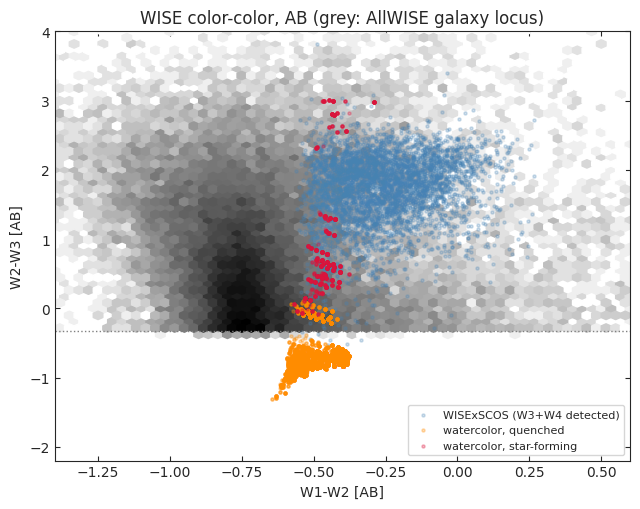

18% of the painted galaxies pass the locus sample's W2-W3 veto; their medians: W1-W2 -0.47, W2-W3  0.31
median W1-W2:  watercolor -0.46 (star-forming -0.46)   AllWISE locus -0.71   WISExSCOS -0.27
median W2-W3:  watercolor -0.73 (star-forming  0.62)   AllWISE locus  0.75   WISExSCOS  1.79     [attenuation only: -1.28]


In [ ]:
#|eval: false

def painted_full_sed(index, z, with_emission=True):
    '''Dusted (+ re-emitted) rest-frame SEDs [Lsun/A] of painted galaxies `index`, all placed at redshift z.'''
    tau_v = engine.tau_v(dust_model, z)[index]
    spec = spec_rest[index] - spec_young[index]*(1.0 - np.exp(-tau_birthcloud(wave_rest, dust_model.tau_bc)))[None, :]
    dusted = attenuate(spec, wave_rest, tau_v, n=dust_model.n, mu=dust_model.mu, apply_bump=dust_model.apply_bump)
    if with_emission:
        l_abs = np.trapezoid(spec_rest[index] - dusted, wave_rest, axis=1)
        templates = np.array([dust_emission_template(logz_s[g], log_ssfr_s[g])[1] for g in index])
        dusted = dusted + np.maximum(l_abs, 0.0)[:, None]*templates
    return dusted

wise_painted = {True: [], False: []}
for k, b in enumerate(engine.bins):
    index = matched['index'][matched['zbin'] == k]
    for with_emission in (True, False):
        wise_painted[with_emission].append(observed_ab_mags(wave_rest, painted_full_sed(index, b['z'], with_emission), b['z'], WISE_FILT))
wise_painted = {key: np.vstack(val) for key, val in wise_painted.items()}

sel_wise = wise_painted[True][:, 0] < 17.1   # ~ WISExSCOS W1 depth (AB)
w12, w23 = (wise_painted[True][:, 0] - wise_painted[True][:, 1])[sel_wise], (wise_painted[True][:, 1] - wise_painted[True][:, 2])[sel_wise]
sf_m = (log_ssfr_s[matched['index']] > -11)[sel_wise]
o_locus, o_xscos = wise_locus['colors'], wise_xscos['colors']   # [W1-W2, W2-W3, W3-W4, W1], AB

fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.hexbin(o_locus[:, 0], o_locus[:, 1], gridsize=60, cmap='Greys', bins='log', mincnt=1, extent=(-1.4, 0.6, -2.2, 4.0))
ax.scatter(o_xscos[:, 0], o_xscos[:, 1], s=5, alpha=0.25, color='steelblue', label='WISExSCOS (W3+W4 detected)')
ax.scatter(w12[~sf_m][::3], w23[~sf_m][::3], s=5, alpha=0.3, color='darkorange', label='watercolor, quenched')
ax.scatter(w12[sf_m][::3], w23[sf_m][::3], s=5, alpha=0.3, color='crimson', label='watercolor, star-forming')
ax.set_xlim(-1.4, 0.6); ax.set_ylim(-2.2, 4.0); ax.axhline(1.5 + WISE_VEGA_TO_AB[1] - WISE_VEGA_TO_AB[2], color='0.5', ls=':', lw=1)  # the locus sample's stellar veto
ax.set_xlabel('W1-W2 [AB]'); ax.set_ylabel('W2-W3 [AB]')
ax.set_title('WISE color-color, AB (grey: AllWISE galaxy locus)'); ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

no_em = wise_painted[False][sel_wise]
in_locus = w23 > 1.5 + WISE_VEGA_TO_AB[1] - WISE_VEGA_TO_AB[2]   # same W2-W3 veto as the AllWISE locus sample
print(f'{in_locus.mean():.0%} of the painted galaxies pass the locus sample\'s W2-W3 veto; their medians: W1-W2 {np.median(w12[in_locus]):5.2f}, W2-W3 {np.median(w23[in_locus]):5.2f}')
print(f'median W1-W2:  watercolor {np.median(w12):5.2f} (star-forming {np.median(w12[sf_m]):5.2f})   AllWISE locus {np.median(o_locus[:, 0]):5.2f}   WISExSCOS {np.median(o_xscos[:, 0]):5.2f}')
print(f'median W2-W3:  watercolor {np.median(w23):5.2f} (star-forming {np.median(w23[sf_m]):5.2f})   AllWISE locus {np.median(o_locus[:, 1]):5.2f}   WISExSCOS {np.median(o_xscos[:, 1]):5.2f}'
      f'     [attenuation only: {np.median(no_em[:, 1] - no_em[:, 2]):5.2f}]')

## GAMA median SED stacks

The test of absolute flux and overall SED shape: real median-stacked `f_nu` [mJy] in `(z, logM*)` bins, on an observed-wavelength grid (the 3.3 um PAH feature sits at 3.3(1+z) um in them). Following `Mocks_v3`'s diagnosis of this comparison, painted galaxies within 0.25 dex of the bin mass are scaled to the bin-centre mass, placed exactly at the bin redshift (no redshift window to bias the median distance) and must pass GAMA's own `r < 19.8` limit.

(z=0.1, logM*=10.0):   72/  72 pass r<19.8;  watercolor/GAMA at 0.75-1, 1-2.5, 2.5-5 um = [0.39 0.44 0.51]
(z=0.1, logM*=10.5):   57/  57 pass r<19.8;  watercolor/GAMA at 0.75-1, 1-2.5, 2.5-5 um = [0.54 0.48 0.52]
(z=0.1, logM*=11.0):   30/  30 pass r<19.8;  watercolor/GAMA at 0.75-1, 1-2.5, 2.5-5 um = [0.70 0.60 0.66]


(z=0.2, logM*=10.5):   52/  57 pass r<19.8;  watercolor/GAMA at 0.75-1, 1-2.5, 2.5-5 um = [0.31 0.31 0.31]
(z=0.2, logM*=11.0):   30/  30 pass r<19.8;  watercolor/GAMA at 0.75-1, 1-2.5, 2.5-5 um = [0.74 0.68 0.67]


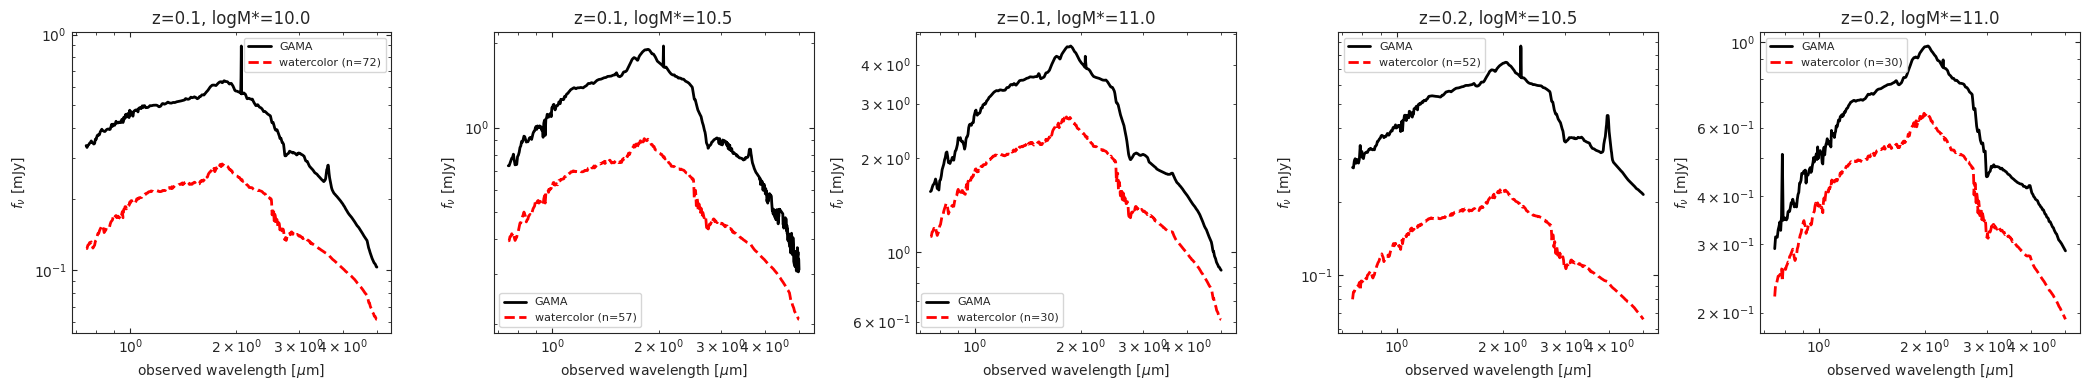

In [ ]:
#|eval: false

GAMA_BINS_TO_CHECK = [(0.1, 10.0), (0.1, 10.5), (0.1, 11.0), (0.2, 10.5), (0.2, 11.0)]
grid_um = gama['wave_um']
fig, axes = plt.subplots(1, len(GAMA_BINS_TO_CHECK), figsize=(4.2*len(GAMA_BINS_TO_CHECK), 4.0))
for ax, (z0, m0) in zip(axes, GAMA_BINS_TO_CHECK):
    index = np.where(np.abs(logmass_s - m0) < 0.25)[0]
    sed = painted_full_sed(index, z0)*(10**(m0 - logmass_s[index]))[:, None]   # every galaxy scaled to the bin-centre mass
    keep = observed_ab_mags(wave_rest, sed, z0, SDSS_FILT)[:, 2] < 19.8
    wave_obs, fnu_mjy = combine_redshift_and_dimming_effect(wave_rest, sed[keep], z0)
    stack = np.interp(grid_um, wave_obs/1e4, np.median(fnu_mjy, axis=0))   # the GAMA grid is OBSERVED wavelength
    real_stack = gama['stacks'][(z0, m0)]
    ax.loglog(grid_um, real_stack, 'k-', lw=2, label='GAMA')
    ax.loglog(grid_um, stack, 'r--', lw=2, label=f'watercolor (n={keep.sum()})')
    ax.set_xlabel(r'observed wavelength [$\mu$m]'); ax.set_ylabel(r'$f_\nu$ [mJy]'); ax.set_title(f'z={z0}, logM*={m0}'); ax.legend(fontsize=8)
    ok = np.isfinite(real_stack) & (real_stack > 0)
    ratio = [np.median((stack/real_stack)[ok & (grid_um > lo) & (grid_um < hi)]) for lo, hi in [(0.75, 1.0), (1.0, 2.5), (2.5, 5.0)]]
    print(f'(z={z0}, logM*={m0}): {keep.sum():4d}/{len(index):4d} pass r<19.8;  watercolor/GAMA at 0.75-1, 1-2.5, 2.5-5 um = {fmt(ratio)}')
plt.tight_layout(); plt.show()

### Is the GAMA offset a mass-scale label or missing light?

GAMA's stellar masses are SED fits (Taylor et al. 2011: BC03, Chabrier), the simulation's are the sum of star particles within 50 kpc. To take the mass scale out of the comparison, give every painted galaxy the mass GAMA *would* measure -- Taylor's `log(M*/L_i) = -0.68 + 0.70 (g-i)` applied to the painted rest-frame colors (`taylor2011_log_mass`) -- and redo the stacks at fixed GAMA-like mass. If the stacks then agree, the simulated galaxies have the right light for their colors and the offset is a difference in what "stellar mass" means; if they still fall short, the painted SEDs are too faint.

GAMA-like (Taylor+2011) minus simulation stellar mass, by simulation mass:
  logM* 9.0-9.5: n=   31   median -0.27 dex   (16-84%: -0.29 .. -0.19);  rest g-i median 1.02
  logM* 9.5-10.0: n=   75   median -0.25 dex   (16-84%: -0.28 .. -0.18);  rest g-i median 1.01
  logM* 10.0-10.5: n=   76   median -0.21 dex   (16-84%: -0.26 .. -0.15);  rest g-i median 1.06
  logM* 10.5-11.0: n=   38   median -0.23 dex   (16-84%: -0.26 .. -0.18);  rest g-i median 1.10
  logM* 11.0-12.0: n=   25   median -0.26 dex   (16-84%: -0.27 .. -0.22);  rest g-i median 1.14
(z=0.1, logM*=10.0) at fixed simulation mass : watercolor/GAMA (1-2.5 um) = 0.44
(z=0.1, logM*=10.0) at fixed GAMA-like mass  : watercolor/GAMA (1-2.5 um) = 0.74


(z=0.1, logM*=10.5) at fixed simulation mass : watercolor/GAMA (1-2.5 um) = 0.48
(z=0.1, logM*=10.5) at fixed GAMA-like mass  : watercolor/GAMA (1-2.5 um) = 0.78
(z=0.1, logM*=11.0) at fixed simulation mass : watercolor/GAMA (1-2.5 um) = 0.60
(z=0.1, logM*=11.0) at fixed GAMA-like mass  : watercolor/GAMA (1-2.5 um) = 1.00


(z=0.2, logM*=10.5) at fixed simulation mass : watercolor/GAMA (1-2.5 um) = 0.31
(z=0.2, logM*=10.5) at fixed GAMA-like mass  : watercolor/GAMA (1-2.5 um) = 0.49
(z=0.2, logM*=11.0) at fixed simulation mass : watercolor/GAMA (1-2.5 um) = 0.68
(z=0.2, logM*=11.0) at fixed GAMA-like mass  : watercolor/GAMA (1-2.5 um) = 1.14


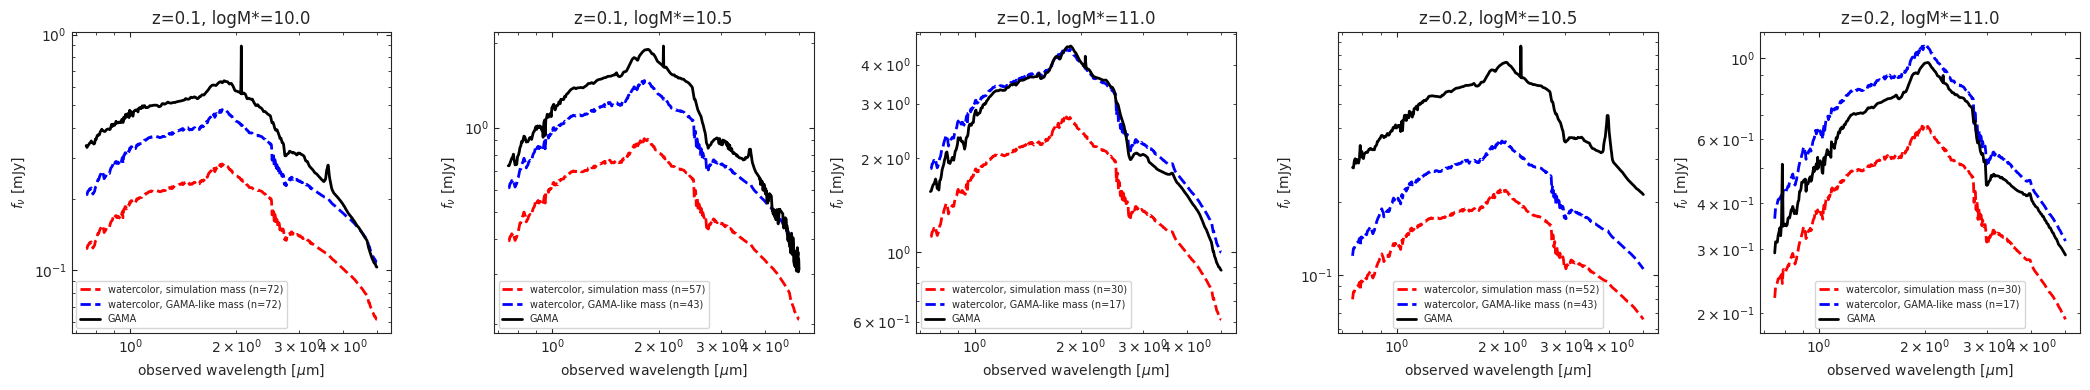

In [ ]:
#|eval: false

abs_mags = rest_frame_absolute_mags(wave_rest, painted_full_sed(np.arange(len(sample_tags)), z_catalog if np.isfinite(z_catalog) else 0.1, with_emission=False), SDSS_FILT)
logmass_gama = taylor2011_log_mass(abs_mags[:, 1], abs_mags[:, 3])
offset = logmass_gama - logmass_s
print('GAMA-like (Taylor+2011) minus simulation stellar mass, by simulation mass:')
for m_lo, m_hi in [(9.0, 9.5), (9.5, 10.0), (10.0, 10.5), (10.5, 11.0), (11.0, 12.0)]:
    s = (logmass_s >= m_lo) & (logmass_s < m_hi)
    if s.sum() > 3:
        print(f'  logM* {m_lo}-{m_hi}: n={s.sum():5d}   median {np.median(offset[s]):+.2f} dex   (16-84%: {np.percentile(offset[s], 16):+.2f} .. {np.percentile(offset[s], 84):+.2f});  rest g-i median {np.median(abs_mags[s, 1] - abs_mags[s, 3]):.2f}')

fig, axes = plt.subplots(1, len(GAMA_BINS_TO_CHECK), figsize=(4.2*len(GAMA_BINS_TO_CHECK), 4.0))
for ax, (z0, m0) in zip(axes, GAMA_BINS_TO_CHECK):
    real_stack = gama['stacks'][(z0, m0)]; ok = np.isfinite(real_stack) & (real_stack > 0)
    for label, logm_use, color in (('simulation mass', logmass_s, 'r'), ('GAMA-like mass', logmass_gama, 'b')):
        index = np.where(np.abs(logm_use - m0) < 0.25)[0]
        if index.size == 0:
            continue
        sed = painted_full_sed(index, z0)*(10**(m0 - logm_use[index]))[:, None]
        keep = observed_ab_mags(wave_rest, sed, z0, SDSS_FILT)[:, 2] < 19.8
        wave_obs, fnu_mjy = combine_redshift_and_dimming_effect(wave_rest, sed[keep], z0)
        stack = np.interp(grid_um, wave_obs/1e4, np.median(fnu_mjy, axis=0))
        ax.loglog(grid_um, stack, '--', color=color, lw=2, label=f'watercolor, {label} (n={keep.sum()})')
        ratio = np.median((stack/real_stack)[ok & (grid_um > 1.0) & (grid_um < 2.5)])
        print(f'(z={z0}, logM*={m0}) at fixed {label:16s}: watercolor/GAMA (1-2.5 um) = {ratio:.2f}')
    ax.loglog(grid_um, real_stack, 'k-', lw=2, label='GAMA')
    ax.set_xlabel(r'observed wavelength [$\mu$m]'); ax.set_ylabel(r'$f_\nu$ [mJy]'); ax.set_title(f'z={z0}, logM*={m0}'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Results

### This run: Frontier-E cluster members (245 galaxies, z = 0.1)

Everything runs on the new layout: geometric membership reproduces `gal_mass_star` to 0.1%, 245 SEDs in 1 s, matching, WISE and GAMA as before. With 95% of the sample quenched, only the red sequence is tested; the numbers ((z, i)-matched to SDSS, 16 / 50 / 84th percentiles):

| | u-g | g-r | r-i | i-z | objective |
|---|---|---|---|---|---|
| SDSS | 1.18 / 1.75 / 2.09 | 0.58 / 0.91 / 1.27 | 0.34 / 0.43 / 0.50 | 0.20 / 0.31 / 0.36 | |
| watercolor, no dust | 1.50 / 1.69 / 1.85 | 0.72 / 0.94 / 1.25 | 0.31 / 0.38 / 0.47 | 0.24 / 0.30 / 0.32 | 0.32 |
| + `Mocks_v3` calibration | 1.85 / 2.13 / 2.33 | 0.98 / 1.24 / 1.49 | 0.48 / 0.60 / 0.70 | 0.39 / 0.50 / 0.56 | 1.11 |
| + bundled watercolor calibration | 1.61 / 1.76 / 1.93 | 0.80 / 1.03 / 1.31 | 0.35 / 0.41 / 0.50 | 0.28 / 0.32 / 0.34 | 0.32 |

The quenched cluster members sit on the SDSS red sequence with essentially no dust (median `tau_V = 0.08`), and the bundled calibration leaves them there; the `Mocks_v3` parameters would redden them by 0.3-0.4 mag in every color. Because the sample has no blue cloud, the painted distributions are much narrower than SDSS's and the objective cannot go below ~0.3 whatever the dust model -- this file cannot recalibrate anything, hence `RECALIBRATE = False`. The other checks behave as expected for a cluster sample: WISE `W2-W3` of the few star-forming members reaches +0.6 (with emission; -1.3 without), the quenched ones sit below the locus sample's veto; the GAMA stacks come out at 0.4-0.7x GAMA at fixed *simulation* mass, the same offset seen for the field sample.

**The GAMA offset is mostly a stellar-mass label.** The mass GAMA's own M/L-color relation (Taylor+2011) assigns to the painted galaxies is 0.21-0.27 dex *below* the simulation's 50 kpc particle mass, uniformly from logM* = 9 to 11.5. Stacking at fixed GAMA-like mass instead brings the z = 0.1 stacks from 0.44 / 0.48 / 0.60x to 0.74 / 0.78 / 1.00x GAMA at logM* = 10.0 / 10.5 / 11.0: the massive bin agrees exactly, the remaining ~0.25 in the lower bins is at the level of the aperture (0.06-0.09 dex, `gal_2Rhalf_stellar_mass` vs 50 kpc) plus the fact that this sample holds only quenched cluster members where GAMA's bins are mostly star-forming galaxies. The z = 0.2 GAMA bins are not usable for this: the stacks themselves break luminosity-distance scaling there (f(0.15)/f(0.2) = 0.95 at logM* = 10 against 1.8 expected, and the mass bins collapse to within 1.3x), because r < 19.8 keeps only their brightest members. So the painted light is right for the painted colors; what differs is what the two sides call stellar mass, by about 0.25 dex -- the same 0.2-0.3 dex `Mocks_v3` found for the supermock.

### Reference: the SciDAC `step_624` field sample (8000 galaxies, z = 0)

The bundled dust calibration was fit on this sample (`RECALIBRATE = True` on that catalog); the matched SDSS comparison it gave:

| | u-g | g-r | r-i | i-z | objective |
|---|---|---|---|---|---|
| SDSS | 1.19 / 1.76 / 2.09 | 0.58 / 0.92 / 1.27 | 0.34 / 0.42 / 0.51 | 0.20 / 0.31 / 0.36 | |
| watercolor, no dust, delta bursts | 0.27 / 1.40 / 1.78 | 0.26 / 0.63 / 1.05 | 0.16 / 0.30 / 0.45 | -0.09 / 0.21 / 0.31 | 0.92 |
| watercolor, no dust, smoothed SFH | 0.53 / 1.44 / 1.80 | 0.29 / 0.69 / 1.09 | 0.18 / 0.30 / 0.43 | 0.07 / 0.22 / 0.32 | 0.69 |
| + `Mocks_v3` dust calibration | 0.50 / 1.03 / 2.07 | 0.40 / 0.59 / 1.14 | 0.32 / 0.45 / 0.63 | -0.28 / 0.24 / 0.47 | 1.00 |
| + watercolor calibration, no `tau_bc` | | | | | 0.20 |
| **+ watercolor calibration (bundled)** | **1.22 / 1.73 / 1.95** | **0.61 / 0.93 / 1.33** | **0.31 / 0.41 / 0.52** | **0.23 / 0.31 / 0.35** | **0.15** |

Medians agree to 0.01-0.03 mag and the widths to a few hundredths in all four colors, and `g-r(z)` follows SDSS bin by bin. The model is `tau_V = 0.26 * 10^(0.41 (logM*-10)) * 10^(0.35 (log sSFR+10))` with lognormal scatter `sigma = 0.12`, a slightly steeper-than-Calzetti curve (`n = -0.30`) and `tau_bc = 0.67` on the <10 Myr stars: median `tau_V = 0.40` for the star-forming galaxies in the SDSS-matched sample. The three Nelder-Mead minima (objective 0.150-0.159) trade `n` against `tau_bc` and `sigma`. What is still off: painted `u-g` stops at ~1.95 where SDSS reaches 2.1 (the old, metal-rich SSPs of the library are not red enough in `u-g`, and the 30% of particles above the grid's 1.58 Zsun can only be clipped to it), and the red sequence is a little too tight. WISE: star-forming galaxies had median `W2-W3 = 1.71` against 1.79 for WISExSCOS (without re-emission it would be -1.16); `W1-W2` is a narrow stripe at -0.44 because the painted SEDs have neither hot dust / AGN nor photometric noise. GAMA: SED shapes match from 0.75 to 5 um, but painted stacks are 0.55-0.65x GAMA at fixed stellar mass -- `Mocks_v3` finds the same 1.5-2x and attributes it to a 0.2-0.3 dex simulation-vs-SED-fit stellar-mass offset.

**About the original hunch** -- that the particle-built populations differ in age / metallicity from what the `Mocks_v3` dust model was calibrated on: the populations themselves are realistic (main sequence, quenched fraction, ages), so that is not what made the first comparison fail; bugs 1-7 above were. But the calibration *is* population-specific, as suspected: applied to these SEDs the `Mocks_v3` parameters are worse than no dust at all, because they put `tau_V ~ 0.8` on every massive galaxy regardless of whether it forms stars.

**DEEP2** is not compared: it needs a z~1 snapshot (see the top of this notebook).

## Scope / next steps

* **A larger Frontier-E extraction** in this layout is what the calibration needs: a field sample (haloes down to ~1e11-1e12 Msun, so that `logM* ~ 9-11.5` galaxies with a star-forming population are represented, not only cluster members), ideally tens of thousands of galaxies; a mass filter on the galaxies (`gal_mass_star > 1e9`) is fine. With it, set `RECALIBRATE = True`. The preferred extraction also carries the galaxy-particle membership (see `01_load_sim_stellar_catalog`).
* The default dust calibration is for z~0 populations against SDSS only (`c = d = 0`). Higher-redshift snapshots should be recalibrated against DEEP2, ideally adding the WISE colors to the objective now that dust emission exists.
* `Mocks_v3`'s `calibrate_dust.py` compares synthetic `g-i` with the surveys' second color column, which is `g-r` (check above). That code was not touched from here.
* `watercolor.paint` still loops over galaxies one at a time; `calc_csp_for_galaxies` + `observed_ab_mags` are the vectorised building blocks for speeding it up (item 3 of the plan).

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()